# 문자, 재귀, 토큰 청킹

**이 노트북에서 할 일**

1. 01절에서 읽은 E01.pdf 2쪽 글을 문자 방식과 재귀 방식으로 나눕니다.
2. 두 방식이 끊은 자리를 견주고 문서 청크마다 출처 기록을 붙입니다.
3. 문서 청크의 조각 수를 세어 정한 한도와 견주고 토큰 방식으로 다시 나눕니다.

**준비물** — API 키가 필요 없습니다. 모델과 임베딩에는 요청을 한 번도 보내지 않습니다.
그래서 예상 비용은 0달러입니다.
조각을 세는 규칙 파일은 처음 실행할 때 한 번 내려받고 그다음부터 저장된 파일을 씁니다.
실행 시간은 패키지 설치를 빼면 10초 안팎입니다.

데이터는 01·02절과 같은 파일 하나입니다.
폴더 `labs/data/rag-corpus/pdf/easy/`의 `E01.pdf` 2쪽입니다.
Ch 9와 이 챕터 01·02절이 읽은 미르시립도서관 이용 안내 문서입니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 설명합니다.
나눌 글 얻기, 문자 방식, 재귀 방식, 두 방식이 끊은 자리 견주기입니다.
6~8절 출처 기록·조각 수 세기·값 바꿔 보기, 9~10절 Before·After는 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다.
pypdf 6.18.0과 langchain-core 1.6.2를 씁니다.
나누는 도구는 langchain-text-splitters 1.1.2이고 조각을 세는 도구는 tiktoken 0.14.0입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

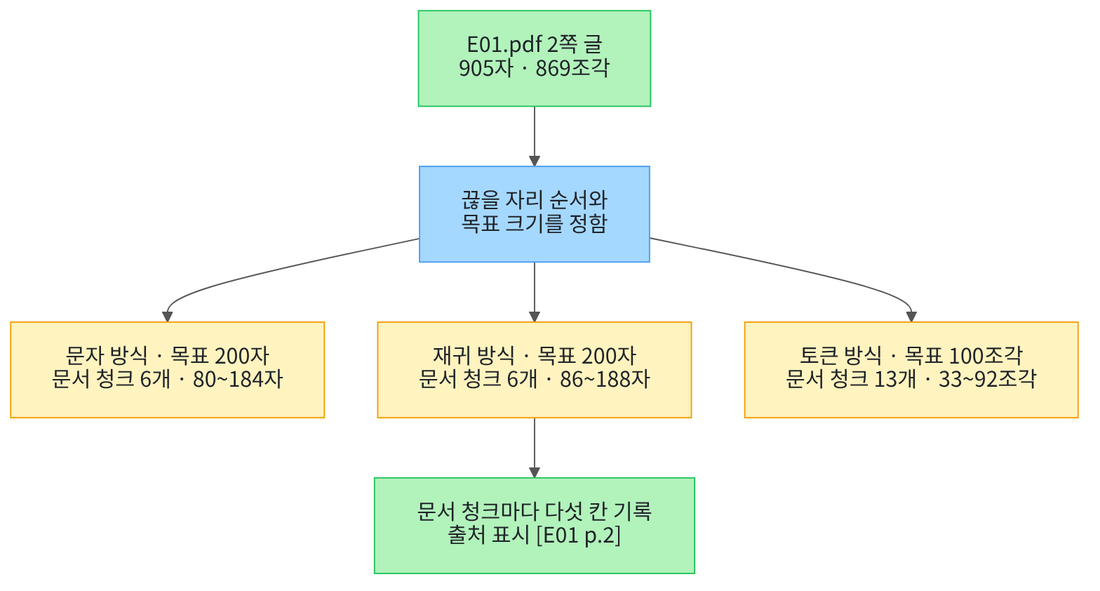

위에서 아래로 봅니다. 파란 상자에서 길이 세 갈래로 갈라집니다.
갈래마다 노란 상자에 문서 청크 수와 길이가 적혀 있습니다.
가운데 갈래 아래 초록 상자는 문서 청크마다 출처 기록을 붙인 자리입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
이 절에서는 PDF를 읽는 도구와 나누는 도구, 조각을 세는 도구를 함께 설치합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "langchain-core==1.6.2" "langchain-text-splitters==1.1.2" "tiktoken==0.14.0"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("tiktoken:", version("tiktoken"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.18.0
langchain-core: 1.6.2
langchain-text-splitters: 1.1.2
tiktoken: 0.14.0


**결과 읽기** — 출력 네 줄은 `pypdf: 6.18.0`, `langchain-core: 1.6.2`,
`langchain-text-splitters: 1.1.2`, `tiktoken: 0.14.0`입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
이름 `CharacterTextSplitter`와 `RecursiveCharacterTextSplitter`가 글을 나누는 도구입니다.
이름 `tiktoken`은 Ch 5에서 배운 조각을 세는 도구입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 8 01·03절 `count_tokens()`·`find_missing_words()`와 Ch 9 02·03절 `load_pdf_pages()`·`make_source_mark()`를 가져옵니다.
01절 `make_source_record()`도 가져옵니다.

함수 `count_tokens()`는 Ch 9 도구 파일 판처럼 조각 세는 규칙 객체를 첫 인자로 받습니다.

In [2]:
# 문서 객체·나누기 도구·조각 세기에 쓸 이름을 불러옵니다
import os

from langchain_core.documents import Document
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
import tiktoken
# Ch 8 01·03절, Ch 9 02·03절, 01절 함수 다섯 개를 도구 파일에서 가져옵니다
from rag_tools import count_tokens, find_missing_words, load_pdf_pages
from rag_tools import make_source_mark, make_source_record

## 2. 나눌 글 얻기

01~04절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.
찾는 폴더는 01·02절과 같은 문서 모음 폴더입니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [3]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`는 PDF 경로와 문서 이름을 받아 쪽마다 `Document` 하나를 만듭니다.

다음 셀은 이 함수로 E01.pdf를 읽고 2쪽 본문을 나눌 글로 삼습니다.
목록 `pages`의 자리 1이 2쪽인 까닭은 로더가 쪽 번호를 1부터 세어 적기 때문입니다.
표시 `"\n"`은 줄바꿈 한 개를 뜻하는 글입니다. 메서드 `split("\n")`은 그 표시마다 글을 잘라 목록으로 만듭니다.

In [4]:
# E01.pdf를 쪽마다 읽고 2쪽 본문을 이 절에서 나눌 글로 삼습니다
corpus_path = root_path + "/labs/data/rag-corpus"
pdf_path = corpus_path + "/pdf/easy/E01.pdf"
pages = load_pdf_pages(pdf_path, "E01")
plain_text = pages[1].page_content
text_lines = plain_text.split("\n")
print("나눌 글의 글자 수:", len(plain_text))
print("나눌 글의 줄 수:", len(text_lines))
print("빈 줄이 있는가:", "\n\n" in plain_text)

나눌 글의 글자 수: 905
나눌 글의 줄 수: 26
빈 줄이 있는가: False


**결과 읽기** — 출력 첫 줄은 `나눌 글의 글자 수: 905`입니다.
다음 줄은 `나눌 글의 줄 수: 26`이고 01절에서 본 값과 같습니다.
마지막 줄 `빈 줄이 있는가: False`를 보세요. 이 글에는 빈 줄이 하나도 없습니다.

빈 줄은 문단이 바뀌는 자리에 흔히 놓입니다.
그런데 pypdf 기본 읽기는 빈 줄을 남기지 않았습니다.
4절에서 끊을 자리 순서를 정할 때 이 사실이 결과를 바꿉니다.

## 3. 문자 방식으로 나누기

**문자 방식**은 경계 하나만 쓰고 길이를 문자 수로 세는 나누기입니다.
클래스 `CharacterTextSplitter`가 그 방식을 맡습니다.
인자 `separator`에 경계 하나를 주고 `chunk_size`에 목표 크기를 줍니다.

메서드 `split_text(글)`을 부를 때 실제로 나뉩니다.
Ch 9 02절에서 쓴 `split_documents()`는 `Document` 목록을 받았고,
이 메서드는 글 하나를 받아 글 목록을 반환합니다.

겹침은 0으로 둡니다. 겹침은 Ch 9 02절에서 배웠고 이 절은 끊는 자리만 보기 때문입니다.
먼저 문서 청크의 길이를 모으는 함수를 만듭니다.

In [5]:
# 문서 청크 목록을 받아 문자 수를 순서대로 모아 반환합니다
def make_length_list(chunk_texts):
    lengths = []
    for chunk_text in chunk_texts:
        lengths.append(len(chunk_text))
    return lengths

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

다음 셀은 줄바꿈 하나를 경계로 주어 목표 200자로 나눕니다.
줄 경계를 고른 까닭은 이 글에 빈 줄이 없기 때문입니다.

In [6]:
# 줄바꿈 하나를 경계로 삼아 목표 200자로 나누고 문서 청크의 문자 수를 봅니다
character_splitter = CharacterTextSplitter(
    separator="\n",
    chunk_size=200,
    chunk_overlap=0,
)
character_texts = character_splitter.split_text(plain_text)
character_lengths = make_length_list(character_texts)
print("문자 방식 문서 청크 수:", len(character_texts))
print("문서 청크별 문자 수:", character_lengths)

문자 방식 문서 청크 수: 6
문서 청크별 문자 수: [156, 156, 184, 172, 152, 80]


**결과 읽기** — 출력 첫 줄은 `문자 방식 문서 청크 수: 6`입니다.
다음 줄 `문서 청크별 문자 수: [156, 156, 184, 172, 152, 80]`이 길이입니다.
여섯 값 모두 목표 크기 안에 들어왔습니다.

마지막 값이 작은 까닭은 남은 글을 마지막 문서 청크에 담기 때문입니다.
목표 크기는 목표일 뿐입니다. 경계로 더 나눌 수 없는 줄이 목표보다 길면 문서 청크가 그 값을 넘습니다.
이번 글에는 그런 줄이 없었습니다.

In [7]:
# 셋째 문서 청크의 본문을 그대로 봅니다
print("문자 방식 셋째 문서 청크의 문자 수:", len(character_texts[2]))
print("문자 방식 셋째 문서 청크:")
print(character_texts[2])

문자 방식 셋째 문서 청크의 문자 수: 184
문자 방식 셋째 문서 청크:
매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
어린이자료실(1층)은 요일과 관계없이 오후 6시에 문을 닫습니다. 디지털자료실(2층)은 오후 9시까지
이용할 수 있습니다.
구역 평일 주말 비고
종합자료실(2층) 09:00~22:00 09:00~18:00


**결과 읽기** — 출력 첫 줄은 `문자 방식 셋째 문서 청크의 문자 수: 184`입니다.
`문자 방식 셋째 문서 청크:` 라벨 줄 아래 여섯 줄이 그 본문입니다.
휴관 안내 두 문장이 함께 있고 그 뒤에 표 머리글과 첫 행이 이어집니다.

마지막 줄은 문장 가운데가 아니라 표의 한 행에서 끝났습니다.
줄을 경계로 썼으니 끊는 자리도 줄 끝 가운데 하나입니다.
01절에서 본 것처럼 기본 읽기는 낱말 사이에 빈칸을 끼워 넣기도 합니다.

## 4. 재귀 방식으로 나누기

**재귀 방식**은 끊을 자리 후보를 여러 개 두고 앞에서부터 차례로 시도하는 나누기입니다.
Ch 9 02절에서 배운 끊을 자리 순서가 그 후보 목록입니다.
큰 경계로 나눈 조각이 목표보다 길면 다음 후보로 내려갑니다.

이번에는 순서를 이름 `separator_order`에 담고 문장 끝을 줄보다 앞에 둡니다.
인자 `keep_separator`에 `"end"`를 주면 경계로 쓴 글이 앞 조각 끝에 남습니다.
값을 주지 않으면 뒤 조각 앞에 붙습니다.

In [8]:
# 문장 끝을 줄보다 앞에 둔 순서로 목표 200자로 나눕니다
separator_order = ["\n\n", ". ", "\n", " ", ""]
recursive_splitter = RecursiveCharacterTextSplitter(
    separators=separator_order,
    chunk_size=200,
    chunk_overlap=0,
    keep_separator="end",
)
recursive_texts = recursive_splitter.split_text(plain_text)
recursive_lengths = make_length_list(recursive_texts)
print("끊을 자리 순서:", separator_order)
print("재귀 방식 문서 청크 수:", len(recursive_texts))
print("문서 청크별 문자 수:", recursive_lengths)

끊을 자리 순서: ['\n\n', '. ', '\n', ' ', '']
재귀 방식 문서 청크 수: 6
문서 청크별 문자 수: [185, 147, 86, 164, 130, 188]


**결과 읽기** — 출력 첫 줄 `끊을 자리 순서:` 뒤에 후보 다섯 개가 보입니다.
다음 줄은 `재귀 방식 문서 청크 수: 6`이고 그다음 줄이 `문서 청크별 문자 수: [185, 147, 86, 164, 130, 188]`입니다.
문서 청크 수는 문자 방식과 같은데 길이는 고르지 않습니다.

셋째 값 `86`은 목표 크기의 절반도 되지 않습니다.
문장을 경계로 쓰면 조각 길이가 문장 길이에 따라 들쭉날쭉해집니다.
첫 후보인 빈 줄은 이 글에 없어서 쓰이지 않았습니다.

In [9]:
# 재귀 방식 둘째와 셋째 문서 청크의 본문을 이어서 봅니다
print("재귀 방식 둘째 문서 청크:")
print(recursive_texts[1])
print("재귀 방식 셋째 문서 청크:")
print(recursive_texts[2])

재귀 방식 둘째 문서 청크:
시민 모두가 자료를 자유롭게 이용하고 배울 수 있도
록 돕는 것을 최우선으로 합니다.
2. 이용 시간
평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. 토요일과 일요일은 오전 9시부터 오후 6
시까지 문을 엽니다.
매주 월요일은 정기 휴관일 입니다.
재귀 방식 셋째 문서 청크:
법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
어린이자료실(1층)은 요일과 관계없이 오후 6시에 문을 닫습니다.


**결과 읽기** — `재귀 방식 둘째 문서 청크:` 라벨 줄 아래 여섯 줄이 첫 본문입니다.
그 마지막 줄은 `매주 월요일은 정기 휴관일 입니다.`입니다.
`재귀 방식 셋째 문서 청크:` 라벨 줄 아래 첫 줄은 `법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인`입니다.

휴관 안내 두 문장이 서로 다른 문서 청크로 갈라졌습니다.
문자 방식 셋째 문서 청크에서는 두 문장이 함께 있었습니다.
문장 끝을 먼저 찾았는데 오히려 이어 읽어야 할 두 문장이 갈라진 것입니다.

## 5. 두 방식이 끊은 자리 견주기

갈라졌는지를 눈으로만 보지 않고 검사로 확인합니다.
Ch 8 03절에서 정한 **지킬 말**을 씁니다. 사람이 원문에서 고른 꼭 남길 말입니다.
이번에는 휴관 안내에서 `정기 휴관일`과 `화요일에도 휴관` 두 개를 골랐습니다.

검사에는 준비 셀에서 가져온 Ch 8 03절 `find_missing_words()`를 씁니다.
이 함수는 빠진 말 목록을 반환합니다. 빈 목록이면 말이 다 들어 있다는 뜻입니다.
다음 셀은 이 함수를 문서 청크마다 불러 번호를 모읍니다.

In [10]:
# 문서 청크 목록에서 지킬 말이 모두 든 문서 청크의 번호를 모아 반환합니다
def find_chunks_with_words(chunk_texts, words):
    found_numbers = []
    number = 1
    for chunk_text in chunk_texts:
        missing = find_missing_words(chunk_text, words)
        if missing == []:
            found_numbers.append(number)
        number = number + 1
    return found_numbers

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

번호는 1부터 셉니다. 사람이 목록을 읽을 때 쓰는 번호와 맞추기 위해서입니다.
02절 로더에서 쪽 번호를 1부터 센 것과 같은 까닭입니다.

In [11]:
# 지킬 말 두 개가 한 문서 청크에 함께 있는 자리를 두 방식에서 찾습니다
closure_words = ["정기 휴관일", "화요일에도 휴관"]
character_found = find_chunks_with_words(character_texts, closure_words)
recursive_found = find_chunks_with_words(recursive_texts, closure_words)
missing_in_second = find_missing_words(recursive_texts[1], closure_words)
print("지킬 말 두 개:", closure_words)
print("문자 방식에서 둘 다 든 문서 청크 번호:", character_found)
print("재귀 방식에서 둘 다 든 문서 청크 번호:", recursive_found)
print("재귀 방식 둘째에서 빠진 말:", missing_in_second)

지킬 말 두 개: ['정기 휴관일', '화요일에도 휴관']
문자 방식에서 둘 다 든 문서 청크 번호: [3]
재귀 방식에서 둘 다 든 문서 청크 번호: []
재귀 방식 둘째에서 빠진 말: ['화요일에도 휴관']


**결과 읽기** — 출력 둘째 줄은 `문자 방식에서 둘 다 든 문서 청크 번호: [3]`입니다.
셋째 줄 `재귀 방식에서 둘 다 든 문서 청크 번호: []`를 보세요. 그런 문서 청크가 없습니다.
마지막 줄은 `재귀 방식 둘째에서 빠진 말: ['화요일에도 휴관']`입니다.

이번 실행에서는 줄을 경계로 쓴 쪽이 두 말을 한 문서 청크에 담았습니다.
그렇다고 문자 방식이 늘 낫다고 적을 수는 없습니다.
글 하나와 목표 크기 하나, 지킬 말 두 개로 한 번 본 결과입니다.

## 6. 문서 청크마다 출처 기록 붙이기

메서드 `split_text()`는 글 목록만 반환합니다.
그래서 이대로는 문서 청크가 어느 파일 어느 쪽에서 왔는지 알 수 없습니다.
01절에서 만든 다섯 칸 출처 기록을 문서 청크마다 따라가게 만듭니다.

같은 스플리터에 `Document`를 넘기면 됩니다.
Ch 9 02절에서 쓴 `split_documents()`가 메타데이터를 문서 청크마다 옮겨 적습니다.
기록은 준비 셀에서 가져온 01절 `make_source_record()`로 만듭니다.

칸은 `doc_id`·`source`·`file_type`·`parser`·`page` 다섯 개입니다.
이번에도 pypdf 기본 읽기로 얻은 글이라 `parser` 칸에 `pypdf-plain`을 적습니다.

출처 표시는 준비 셀에서 가져온 Ch 9 03절 `make_source_mark()`로 만듭니다. 기록의 `doc_id`와 `page` 두 칸만 읽습니다.
03절 `make_unit_mark()`와 04절 `make_section_mark()`는 쪽이 없는 형식에 쓰는 함수입니다.
이 절의 글은 PDF 한 쪽에서 왔으므로 쪽을 읽는 함수를 씁니다.

In [12]:
# 2쪽 Document를 만들어 같은 재귀 스플리터로 나누고 기록이 따라가는지 봅니다
page_two_record = make_source_record(pdf_path, 2, "pypdf-plain")
page_two_document = Document(page_content=plain_text, metadata=page_two_record)
chunk_documents = recursive_splitter.split_documents([page_two_document])
first_chunk = chunk_documents[0]
last_chunk = chunk_documents[5]
print("문서 청크 Document 수:", len(chunk_documents))
print("첫 문서 청크의 메타데이터 칸 수:", len(first_chunk.metadata))
print("첫 문서 청크의 출처 표시:", make_source_mark(first_chunk))
print("마지막 문서 청크의 출처 표시:", make_source_mark(last_chunk))
print("첫 문서 청크 본문이 앞의 결과와 같은가:", first_chunk.page_content == recursive_texts[0])

문서 청크 Document 수: 6
첫 문서 청크의 메타데이터 칸 수: 5
첫 문서 청크의 출처 표시: [E01 p.2]
마지막 문서 청크의 출처 표시: [E01 p.2]
첫 문서 청크 본문이 앞의 결과와 같은가: True


**결과 읽기** — 출력 첫 줄은 `문서 청크 Document 수: 6`입니다.
다음 줄 `첫 문서 청크의 메타데이터 칸 수: 5`를 보세요. 다섯 칸이 그대로 따라왔습니다.
셋째·넷째 줄은 `첫 문서 청크의 출처 표시: [E01 p.2]`와 `마지막 문서 청크의 출처 표시: [E01 p.2]`입니다.
마지막 줄은 `첫 문서 청크 본문이 앞의 결과와 같은가: True`입니다.

여섯 문서 청크의 출처 표시가 모두 같습니다.
쪽 안에서 몇 번째 문서 청크인지는 이 기록에 없습니다.
문서 청크마다 이름을 하나 더 붙이는 일은 이 절에서 하지 않았습니다.

## 7. 조각 수 세기

Ch 5에서 배운 **조각**은 모델이 글을 세는 단위입니다.
Ch 8에서는 입력 예산을 조각 수로 나눠 두었습니다.
그래서 근거로 넣을 문서 청크도 문자 수가 아니라 조각 수로 세어 봐야 합니다.

Ch 9 02절에서 임베딩 모델 이름으로 얻은 규칙 이름이 `cl100k_base`였습니다.
함수 `tiktoken.get_encoding()`에 그 이름을 바로 주면 같은 규칙을 얻습니다.

In [13]:
# 조각을 세는 규칙을 이름에 담습니다. 조각 수는 준비 셀에서 가져온 count_tokens()로 셉니다
encoding = tiktoken.get_encoding("cl100k_base")
print("조각 세는 규칙 이름:", encoding.name)

조각 세는 규칙 이름: cl100k_base


**결과 읽기** — 출력 줄은 `조각 세는 규칙 이름: cl100k_base`입니다. Ch 9 02절에서 얻은 규칙과 같은 이름입니다.

준비 셀에서 가져온 Ch 8 01절 `count_tokens()`는 이 규칙 객체와 글을 받아 조각 수를 반환합니다.
함수 안에서 메서드 `encode()`가 글을 조각 목록으로 바꾸고, 그 길이가 조각 수입니다.
다음 셀은 문서 청크 목록의 조각 수를 모으는 함수를 만듭니다.

In [14]:
# 문서 청크 목록을 받아 조각 수를 순서대로 모아 반환합니다
def make_token_list(chunk_texts):
    token_counts = []
    for chunk_text in chunk_texts:
        token_counts.append(count_tokens(encoding, chunk_text))
    return token_counts

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

함수가 함수를 부르는 모양입니다. 02·04절에서도 같은 모양을 썼습니다.
조각 세는 규칙 `encoding`은 함수 밖에서 읽습니다. Ch 5에서 배운 모양입니다.
다음 셀은 나눌 글 전체와 재귀 방식 문서 청크의 조각 수를 셉니다.

In [15]:
# 나눌 글 전체와 재귀 방식 문서 청크의 조각 수를 셉니다
whole_tokens = count_tokens(encoding, plain_text)
recursive_tokens = make_token_list(recursive_texts)
print("나눌 글 전체의 조각 수:", whole_tokens)
print("재귀 방식 문서 청크의 조각 수:", recursive_tokens)
print("재귀 방식 문서 청크의 문자 수:", recursive_lengths)

나눌 글 전체의 조각 수: 869
재귀 방식 문서 청크의 조각 수: [190, 133, 92, 155, 120, 177]
재귀 방식 문서 청크의 문자 수: [185, 147, 86, 164, 130, 188]


**결과 읽기** — 출력 첫 줄은 `나눌 글 전체의 조각 수: 869`입니다.
다음 줄 `재귀 방식 문서 청크의 조각 수: [190, 133, 92, 155, 120, 177]`을 보세요.
마지막 줄 `재귀 방식 문서 청크의 문자 수: [185, 147, 86, 164, 130, 188]`과 번호별로 견줍니다.

첫 문서 청크는 185자인데 조각 수가 190입니다.
셋째 문서 청크는 86자인데 조각 수가 92입니다.
이 글에서는 조각 수가 문자 수보다 큰 자리가 있었습니다. 두 값은 같은 단위가 아닙니다.

## 8. 값 하나만 바꿔 보기

바꾸는 값은 끊을 자리 순서 하나입니다. 문장 끝을 줄 뒤로 옮깁니다.
목표 크기와 겹침은 4절과 같게 둡니다.

실행 전에 예상합니다. 끊는 자리가 문장 끝에서 줄 끝으로 옮겨질 것입니다.

In [16]:
# 끊을 자리 순서만 바꿔 같은 목표 크기로 다시 나눕니다
changed_order = ["\n\n", "\n", ". ", " ", ""]
changed_splitter = RecursiveCharacterTextSplitter(
    separators=changed_order,
    chunk_size=200,
    chunk_overlap=0,
    keep_separator="end",
)
changed_texts = changed_splitter.split_text(plain_text)
print("바꾼 끊을 자리 순서:", changed_order)
print("문서 청크별 문자 수:", make_length_list(changed_texts))
print("문자 방식 결과와 같은가:", changed_texts == character_texts)

바꾼 끊을 자리 순서: ['\n\n', '\n', '. ', ' ', '']
문서 청크별 문자 수: [156, 156, 184, 172, 152, 80]
문자 방식 결과와 같은가: True


**결과 읽기** — 출력 둘째 줄은 `문서 청크별 문자 수: [156, 156, 184, 172, 152, 80]`입니다.
3절 문자 방식의 길이와 같은 값입니다.
마지막 줄 `문자 방식 결과와 같은가: True`를 보세요. 본문까지 모두 같았습니다.

이 글에는 빈 줄이 없어서 줄이 첫 경계로 쓰였습니다.
그래서 재귀 방식이 문자 방식과 같은 자리에서 끊었습니다.
다른 글에서도 두 방식이 늘 같은지는 이번에 실행하지 않았습니다.

## 9. 일부러 실패해 보기

검색한 문서 청크는 모델에 근거로 넣습니다.
Ch 8에서 입력 예산을 조각 수로 나눈 것처럼 근거 자리도 조각 수로 셉니다.
이 절에서는 근거 세 개에 450조각을 주기로 정했습니다. Ch 8 01절 예산(가용분 440)과는 다른 값이고, 한도를 예산에서 나누는 방법만 같습니다. 그렇게 정하면 문서 청크 하나는 150조각까지입니다.

Before 셀은 「문자 수를 200자로 맞췄으니 조각 수도 한도 안일 것」이라고 보는 자리입니다.
7절에서 센 조각 수를 그 한도와 견줘 봅니다.

In [17]:
# 조각 수 목록에서 한도를 넘은 자리의 번호를 모아 반환합니다
def find_over_limit(token_counts, limit):
    over_numbers = []
    number = 1
    for token_count in token_counts:
        if token_count > limit:
            over_numbers.append(number)
        number = number + 1
    return over_numbers

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

비교는 「넘으면」이라 한도와 같은 값은 넘은 것으로 세지 않습니다.
다음 셀은 재귀 방식 문서 청크의 조각 수를 한도와 견줍니다.

In [18]:
# 재귀 방식 문서 청크의 조각 수를 정한 한도와 견줍니다
token_limit = 150
recursive_over = find_over_limit(recursive_tokens, token_limit)
print("문서 청크 하나의 조각 수 한도:", token_limit)
print("재귀 방식 문서 청크의 조각 수:", recursive_tokens)
print("한도를 넘은 문서 청크 번호:", recursive_over)

문서 청크 하나의 조각 수 한도: 150
재귀 방식 문서 청크의 조각 수: [190, 133, 92, 155, 120, 177]
한도를 넘은 문서 청크 번호: [1, 4, 6]


**결과 읽기** — 출력 첫 줄은 `문서 청크 하나의 조각 수 한도: 150`입니다.
다음 줄은 `재귀 방식 문서 청크의 조각 수: [190, 133, 92, 155, 120, 177]`입니다.
마지막 줄 `한도를 넘은 문서 청크 번호: [1, 4, 6]`을 보세요. 여섯 개 가운데 세 개가 넘었습니다.

문자 수는 여섯 개 모두 목표 200자 안이었습니다.
그런데 조각 수로 보면 한도를 넘는 문서 청크가 생겼습니다.
문자 수를 맞춘 것으로 조각 수 한도를 지켰다고 볼 수 없습니다.

## 10. 고쳐서 다시 실행하기

**토큰 방식**은 목표 크기를 조각 수로 재는 나누기입니다.
클래스 이름에 점을 붙여 부르는 `from_tiktoken_encoder()`가 그런 스플리터를 만듭니다.
인자 `encoding_name`에 규칙 이름을 주고 `chunk_size`에 조각 수를 줍니다.

끊을 자리 순서는 4절과 같게 둡니다. 바뀌는 것은 길이를 세는 기준 하나입니다.

In [19]:
# 목표 크기를 조각 수로 재는 스플리터를 만들어 같은 글을 다시 나눕니다
token_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    separators=separator_order,
    chunk_size=100,
    chunk_overlap=0,
    keep_separator="end",
)
token_texts = token_splitter.split_text(plain_text)
print("토큰 방식 문서 청크 수:", len(token_texts))
print("문서 청크별 문자 수:", make_length_list(token_texts))

토큰 방식 문서 청크 수: 13
문서 청크별 문자 수: [52, 49, 82, 92, 54, 86, 77, 86, 85, 44, 62, 88, 36]


**결과 읽기** — 출력 첫 줄은 `토큰 방식 문서 청크 수: 13`입니다.
다음 줄 `문서 청크별 문자 수: [52, 49, 82, 92, 54, 86, 77, 86, 85, 44, 62, 88, 36]`이 길이입니다.
목표 크기를 조각 수 100으로 주었더니 문서 청크가 여섯 개에서 열세 개로 늘었습니다.

다음 셀은 이 문서 청크의 조각 수를 같은 한도와 견줍니다.

In [20]:
# 토큰 방식 문서 청크의 조각 수를 같은 한도와 견줍니다
token_counts = make_token_list(token_texts)
token_over = find_over_limit(token_counts, token_limit)
print("문서 청크 하나의 조각 수 한도:", token_limit)
print("문서 청크별 조각 수:", token_counts)
print("한도를 넘은 문서 청크 번호:", token_over)
assert token_over == []

문서 청크 하나의 조각 수 한도: 150
문서 청크별 조각 수: [54, 52, 83, 81, 52, 92, 75, 79, 76, 43, 59, 85, 33]
한도를 넘은 문서 청크 번호: []


**결과 읽기** — 출력 둘째 줄은 `문서 청크별 조각 수: [54, 52, 83, 81, 52, 92, 75, 79, 76, 43, 59, 85, 33]`입니다.
목록에서 가장 큰 값은 `92`이고 가장 작은 값은 `33`입니다.
마지막 줄 `한도를 넘은 문서 청크 번호: []`를 보세요. 넘은 문서 청크가 없습니다. `assert`도 통과했습니다.

목표를 조각 수로 주었으니 조각 수 한도는 지켜집니다.
대신 문서 청크가 많아지고 하나에 담기는 글이 짧아졌습니다.
어느 기준이 검색에 더 나은지는 이 절에서 재지 않았습니다.

## 11. 정리

1. 같은 글 905자를 문자 방식과 재귀 방식으로 나누니 문서 청크가 각각 여섯 개였습니다. 길이는 `[156, 156, 184, 172, 152, 80]`과 `[185, 147, 86, 164, 130, 188]`이었습니다.
2. 지킬 말 두 개가 함께 든 문서 청크는 문자 방식에 하나 있었고 재귀 방식에는 없었습니다.
3. `split_documents()`로 나누면 다섯 칸 출처 기록이 문서 청크마다 따라왔고 표시는 모두 `[E01 p.2]`였습니다.
4. 재귀 방식 문서 청크의 조각 수는 `[190, 133, 92, 155, 120, 177]`이라 한도 150을 셋이 넘었습니다.
5. 목표를 조각 수 100으로 준 토큰 방식은 문서 청크 열세 개가 되고 가장 큰 것이 92조각이었습니다.

다음 06절에서는 길이가 아니라 글의 구조와 뜻으로 끊는 자리를 정합니다.
제목 표시가 바뀌는 자리에서 나누고, 문장 사이의 거리로 나누는 방법을 견줍니다.
그때도 이 절에서 본 대로 나눈 결과의 수와 길이를 함께 확인합니다.